In [1]:

# Standard libraries
import time

# Numerical computation and plotting
import numpy as np
import matplotlib.pyplot as plt

# Deep learning
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam



In [2]:
#Experiment parameters
#Training sample sizes: 10 values from 100 to 10,000, on a log scale
sample_sizes = np.logspace(2, 4, 10).astype(int)

#Test-set size: 20% of the training-set size
test_fraction = 0.2


In [3]:
#This is the function that we approximate
def funct(x):
    g = np.cos(10*x) * np.exp(-np.pi*x**2)
    return g



In [4]:
#Generate random sample points uniformly on [-1, 1]
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    """Generate independent uniform samples on [-1, 1]."""
    return rng.uniform(-1, 1, size=int(n_samples))

In [5]:

# Create a simple feedforward neural network

def create_simple_NN(X_samp, labels, L, activation='relu'):
    """
    Create a feedforward neural network.

    Parameters:
        X_samp: Sample input data (not used in model definition).
        labels: Training labels (not used in model definition).
        L: Tuple or list where L[0] is the number of hidden layers
           and L[1] is the number of neurons per hidden layer.
        activation: Activation function for hidden layers.

    Returns:
        A compiled-ready Keras model with the specified architecture.
    """

    # Define the input layer
    model_input = Input(shape=(1,))
    x = model_input

    # Create the hidden layers
    for i in range(int(L[0])):
        x = Dense(
    int(L[1]),
    activation=activation,
    kernel_initializer=tf.keras.initializers.RandomNormal(
        mean=0.0, stddev=0.1
    )
    )(x)

    # Define the output layer
    out = Dense(1)(x)

    # Create the model
    model = Model(inputs=model_input, outputs=out)

    return model



In [6]:
# Parameters for training

initial_learning_rate = 0.001  # Initial learning rate
decay_steps = 1000              # Steps before applying learning-rate decay
decay_rate = 0.85               # Learning-rate decay factor
staircase = True                # Apply decay in discrete steps

#final_epochs = 1000
final_epochs = 150             # Maximum number of training epochs
total_runs = 20                 # Number of independent repetitions

VAL_SPLIT = 0                   # Fraction of training data used for validation
BATCH_SIZE = 50                 # Number of samples per training batch

In [7]:
# Generate the neural network architectures
def Archit(K):
    Array = np.arange(1, K[0] + 1)
    Lay_x_Neu = np.column_stack((Array, K[1] * Array))
    return Lay_x_Neu

Lay_x_Neu = Archit([10, 10])

#print(Lay_x_Neu)

In [8]:

# Run the deep-learning experiments
start_time = time.time()

# Store test RMSE and training history
results = np.zeros((len(Lay_x_Neu), len(sample_sizes), total_runs))
history = np.zeros((len(Lay_x_Neu), final_epochs, total_runs))

total_iterations = total_runs * len(sample_sizes) * len(Lay_x_Neu)
counter = 0

# Exponentially decaying learning-rate schedule
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=initial_learning_rate,
    decay_steps=decay_steps,
    decay_rate=decay_rate,
    staircase=staircase
)

for run in range(total_runs):
    for i, n_samples in enumerate(sample_sizes):

        # Generate training samples and target values
        training_sample = generate_samples(n_samples).reshape(-1, 1)
        values = funct(training_sample).reshape(-1, 1)

        # Generate an independent test set
        n_test = int(test_fraction * n_samples)
        test_sample = generate_samples(n_test).reshape(-1, 1)
        test_values = funct(test_sample).reshape(-1, 1)

        for j, architecture in enumerate(Lay_x_Neu):

            # Release the previous model's Keras state
            tf.keras.backend.clear_session()

            # Create a fresh optimizer for this model
            Optimizer = Adam(
                learning_rate=lr_schedule,
                beta_1=0.9,
                beta_2=0.999,
                epsilon=1e-7
            )

            # Create and compile the neural network
            model = create_simple_NN(
                training_sample, values, architecture
            )

            model.compile(
                loss="mean_squared_error",
                optimizer=Optimizer,
                metrics=["mean_squared_error"],
                steps_per_execution=10
            )

            # Train the model
            hist = model.fit(
                training_sample,
                values,
                validation_split=VAL_SPLIT,
                epochs=final_epochs,
                batch_size=BATCH_SIZE,
                shuffle=True,
                verbose=0
            )

            # Save training history for the largest sample size
            if i == len(sample_sizes) - 1:
                history[j, :, run] = hist.history["mean_squared_error"]

            # Evaluate test RMSE
            test_mse = model.evaluate(
                test_sample, test_values, verbose=0
            )[0]

            results[j, i, run] = np.sqrt(test_mse)

            # Update progress
            counter += 1

            if counter % 10 == 0 or counter == total_iterations:
                elapsed = time.time() - start_time
                estimated_total = elapsed * total_iterations / counter
                remaining = estimated_total - elapsed

                print(
                    f"{counter}/{total_iterations} fits "
                    f"({100 * counter / total_iterations:.1f}%) | "
                    f"Elapsed: {elapsed / 60:.1f} min | "
                    f"Remaining: {remaining / 60:.1f} min"
                )

print(f"All experiments completed in {(time.time() - start_time) / 60:.1f} minutes.")



10/2000 fits (0.5%) | Elapsed: 0.7 min | Remaining: 141.0 min
20/2000 fits (1.0%) | Elapsed: 1.5 min | Remaining: 144.6 min
30/2000 fits (1.5%) | Elapsed: 2.2 min | Remaining: 146.0 min
40/2000 fits (2.0%) | Elapsed: 3.0 min | Remaining: 147.5 min
50/2000 fits (2.5%) | Elapsed: 3.9 min | Remaining: 150.3 min
60/2000 fits (3.0%) | Elapsed: 4.8 min | Remaining: 155.0 min
70/2000 fits (3.5%) | Elapsed: 5.9 min | Remaining: 162.1 min
80/2000 fits (4.0%) | Elapsed: 7.2 min | Remaining: 173.1 min
90/2000 fits (4.5%) | Elapsed: 8.9 min | Remaining: 189.6 min
100/2000 fits (5.0%) | Elapsed: 11.1 min | Remaining: 211.6 min
110/2000 fits (5.5%) | Elapsed: 11.8 min | Remaining: 203.3 min
120/2000 fits (6.0%) | Elapsed: 12.6 min | Remaining: 196.9 min
130/2000 fits (6.5%) | Elapsed: 13.3 min | Remaining: 191.6 min
140/2000 fits (7.0%) | Elapsed: 14.1 min | Remaining: 187.3 min
150/2000 fits (7.5%) | Elapsed: 14.9 min | Remaining: 184.3 min
160/2000 fits (8.0%) | Elapsed: 15.9 min | Remaining: 182

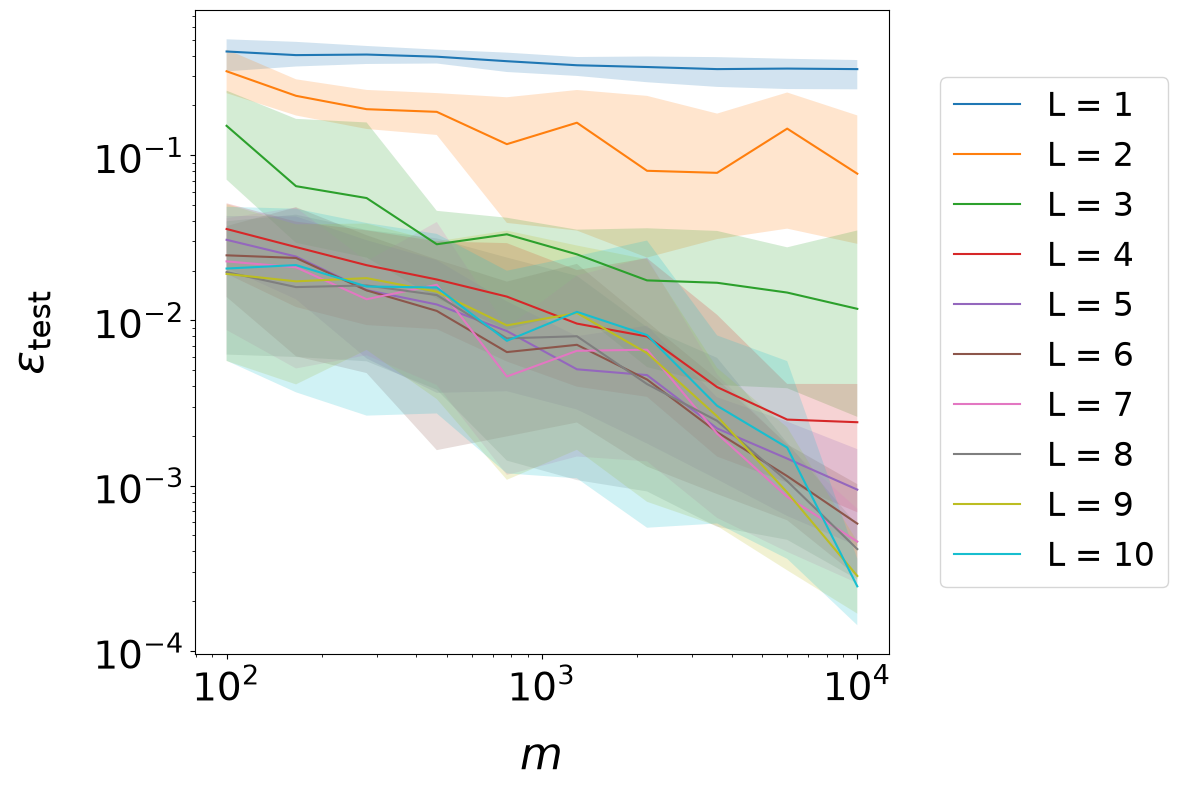

In [9]:
#Plot test error over training sample sizes
plt.figure(figsize=(12, 8))

results_mean = np.mean(results, axis=2)
results_lower = np.percentile(results, 5, axis=2)
results_upper = np.percentile(results, 95, axis=2)

for i in range(len(Lay_x_Neu)):
    plt.loglog(
        sample_sizes,
        results_mean[i, :],
        label=f'L = {int(Lay_x_Neu[i, 0])}'
    )
    plt.fill_between(
        sample_sizes,
        results_lower[i, :],
        results_upper[i, :],
        alpha=0.2
    )

plt.xlabel(r'$m$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{\mathrm{test}}$', fontsize=32, labelpad=28)

plt.tick_params(axis='both', which='major', labelsize=28)
plt.tick_params(axis='both', which='minor', labelsize=28)

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),
    ncol=1
)

plt.tight_layout()
plt.savefig("errorNN1D.pdf", bbox_inches="tight")
plt.show()
